<a href="https://colab.research.google.com/github/tlgus9989-art/bigdataHackathon/blob/main/%EA%B8%B0%EB%A7%90_%ED%95%B4%EC%BB%A4%ED%86%A4_%EA%B0%9C%EC%84%A0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
from pathlib import Path
from tempfile import mkdtemp
from zipfile import ZipFile
import hashlib
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

drive.mount("/content/drive")
ZIP_PATH = Path("/content/drive/MyDrive/빅데이터프로그래밍/기말고사 해커톤/archive.zip")
work = Path(mkdtemp(prefix="trash_", dir="/content"))
with ZipFile(ZIP_PATH) as archive:
    archive.extractall(work)

root = next(p.parent for p in work.rglob("paper") if (p.parent / "plastic").is_dir())
source = datasets.ImageFolder(root)
assert len(source.classes) == 12, source.classes
seed = 12345
torch.manual_seed(seed)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device, root, len(source), source.classes)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
cuda /content/trash_qdbkz2ru/garbage_classification 15515 ['battery', 'biological', 'brown-glass', 'cardboard', 'clothes', 'green-glass', 'metal', 'paper', 'plastic', 'shoes', 'trash', 'white-glass']


In [ ]:
from collections import defaultdict

by_hash = defaultdict(list)
for idx, (path, label) in enumerate(source.samples):
    digest = hashlib.sha256(Path(path).read_bytes()).digest()
    by_hash[digest].append((idx, label))

by_class = defaultdict(list)
for group in by_hash.values():
    if len({label for _, label in group}) == 1:
        idx, label = group[0]
        by_class[label].append(idx)

rng = torch.Generator().manual_seed(seed)
train_ids, val_ids, test_ids = [], [], []
print("클래스 | 학습 | 검증 | 시험")
for label, name in enumerate(source.classes):
    ids = by_class[label]
    ids = [ids[i] for i in torch.randperm(len(ids), generator=rng).tolist()]
    n_val = n_test = int(len(ids) * 0.15)
    n_train = len(ids) - n_val - n_test
    train_ids.extend(ids[:n_train])
    val_ids.extend(ids[n_train:n_train + n_val])
    test_ids.extend(ids[n_train + n_val:])
    print(name, n_train, n_val, n_test)
print("중복·라벨 충돌로 제외:", len(source) - len(train_ids) - len(val_ids) - len(test_ids))

클래스 | 학습 | 검증 | 시험
battery 663 141 141
biological 691 147 147
brown-glass 425 91 91
cardboard 625 133 133
clothes 3728 798 798
green-glass 430 92 92
metal 538 115 115
paper 736 157 157
plastic 605 129 129
shoes 1385 296 296
trash 489 104 104
white-glass 542 115 115
중복·라벨 충돌로 제외: 22


In [ ]:
from datetime import datetime
import json

run_dir = ZIP_PATH.parent / ("trash_course_" + datetime.now().strftime("%Y%m%d_%H%M%S_%f"))
run_dir.mkdir()

plain_tf = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor()
])
aug_tf = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.RandomRotation(10),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor()
])
plain_data = datasets.ImageFolder(root, transform=plain_tf)
aug_data = datasets.ImageFolder(root, transform=aug_tf)

train_eval_loader = DataLoader(Subset(plain_data, train_ids), batch_size=64, shuffle=False)
val_loader = DataLoader(Subset(plain_data, val_ids), batch_size=64, shuffle=False)
test_loader = DataLoader(Subset(plain_data, test_ids), batch_size=64, shuffle=False)

splits = {"train": train_ids, "val": val_ids, "test": test_ids}
manifest = {name: [{"path": str(Path(source.samples[i][0]).relative_to(root)),
                    "label": source.samples[i][1]} for i in ids] for name, ids in splits.items()}
(run_dir / "splits.json").write_text(json.dumps(
    {"classes": source.classes, "seed": seed, "splits": manifest},
    ensure_ascii=False, indent=2), encoding="utf-8")
print("저장 폴더:", run_dir)

저장 폴더: /content/drive/MyDrive/빅데이터프로그래밍/기말고사 해커톤/trash_course_20261118_110322_165663


In [ ]:
import torch.nn.functional as F

class CNN(nn.Module):
    def __init__(self, n_classes, dropout=0.0, batchnorm=False):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 32, 3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        self.batchnorm = batchnorm
        if batchnorm:
            self.bn1 = nn.BatchNorm2d(32)
            self.bn2 = nn.BatchNorm2d(64)
        self.fc1 = nn.Linear(64 * 16 * 16, 256)
        self.fc2 = nn.Linear(256, n_classes)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        x = self.conv1(x)
        if self.batchnorm:
            x = self.bn1(x)
        x = F.max_pool2d(F.relu(x), 2)     # (32, 32, 32)

        x = self.conv2(x)
        if self.batchnorm:
            x = self.bn2(x)
        x = F.max_pool2d(F.relu(x), 2)     # (64, 16, 16)

        x = x.flatten(1)                   # 배치 차원을 유지하며 펼치기
        x = self.dropout(x)
        x = F.relu(self.fc1(x))
        return self.fc2(self.dropout(x))   # 클래스별 점수

In [ ]:
model = CNN(len(source.classes)).to(device)
print(model)
bx, by = next(iter(val_loader))
model.eval()
with torch.no_grad():
    out = model(bx.to(device))
print("입력:", bx.shape, "정답:", by.shape, "출력:", out.shape)

CNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (fc1): Linear(in_features=16384, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=12, bias=True)
  (dropout): Dropout(p=0.0, inplace=False)
)
입력: torch.Size([64, 3, 64, 64]) 정답: torch.Size([64]) 출력: torch.Size([64, 12])


In [ ]:
loss_fn = nn.CrossEntropyLoss()

def measure(model, loader):
    model.eval()
    loss_sum = correct = total = 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss_sum += loss_fn(out, y).item() * y.numel()
            correct += (out.argmax(dim=1) == y).sum().item()
            total += y.numel()
    return loss_sum / total, correct / total

In [ ]:
def train_model(name, training_data, dropout, batchnorm, lr):
    torch.manual_seed(seed)
    model = CNN(len(source.classes), dropout, batchnorm).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    train_loader = DataLoader(
        Subset(training_data, train_ids), batch_size=64, shuffle=True,
        generator=torch.Generator().manual_seed(seed)
    )
    best_loss = float("inf")
    stale = 0
    history = []
    checkpoint = run_dir / (name + ".pt")
    print("\n실험:", name)

    for epoch in range(1, 26):
        model.train()
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = loss_fn(out, y)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        train_loss, train_acc = measure(model, train_eval_loader)
        val_loss, val_acc = measure(model, val_loader)
        history.append({"epoch": epoch, "train_loss": train_loss, "train_acc": train_acc,
                        "val_loss": val_loss, "val_acc": val_acc})
        print(f"{epoch:02d}회 | 학습 손실 {train_loss:.4f} 정확도 {train_acc:.2%} | "
              f"검증 손실 {val_loss:.4f} 정확도 {val_acc:.2%} | "
              f"정확도 차이 {(train_acc-val_acc)*100:.2f}%p")

        if val_loss < best_loss:
            best_loss = val_loss
            best_epoch = epoch
            best_acc = val_acc
            stale = 0
            torch.save({"state": model.state_dict(), "config": {"name": name, "dropout": dropout, "batchnorm": batchnorm, "lr": lr, "augment": training_data is aug_data},
                        "classes": source.classes, "epoch": epoch,
                        "val_loss": val_loss, "seed": seed}, checkpoint)
        else:
            stale += 1
        (run_dir / (name + "_history.json")).write_text(
            json.dumps(history, indent=2), encoding="utf-8")
        if stale >= 4:
            print("검증 손실이 4회 연속 개선되지 않아 학습 종료")
            break

    return {"name": name, "checkpoint": str(checkpoint),
                    "val_loss": best_loss, "val_acc": best_acc, "epoch": best_epoch}

In [ ]:
basic = train_model("basic", plain_data, dropout=0.0, batchnorm=False, lr=0.001)
combo = train_model("combo", aug_data, dropout=0.3, batchnorm=True, lr=0.001)
combo_low_lr = train_model("combo_low_lr", aug_data, dropout=0.3, batchnorm=True, lr=0.0003)

results = [basic, combo, combo_low_lr]
print("\n설정별 최적 회차 결과")
for row in results:
    print(row["name"], "| 회차", row["epoch"],
          f'| 검증 손실 {row["val_loss"]:.4f} | 검증 정확도 {row["val_acc"]:.2%}')
chosen = min(results, key=lambda row: row["val_loss"])
print("검증 손실 기준 선택:", chosen["name"])
(run_dir / "comparison.json").write_text(json.dumps(results, indent=2), encoding="utf-8")


실험: basic
01회 | 학습 손실 1.0871 정확도 63.36% | 검증 손실 1.1369 정확도 60.91% | 정확도 차이 2.45%p
02회 | 학습 손실 0.7612 정확도 75.39% | 검증 손실 0.8837 정확도 71.35% | 정확도 차이 4.03%p
03회 | 학습 손실 0.6011 정확도 80.48% | 검증 손실 0.8042 정확도 73.73% | 정확도 차이 6.76%p
04회 | 학습 손실 0.5123 정확도 83.37% | 검증 손실 0.8048 정확도 73.77% | 정확도 차이 9.60%p
05회 | 학습 손실 0.4235 정확도 85.81% | 검증 손실 0.8043 정확도 74.81% | 정확도 차이 11.00%p
06회 | 학습 손실 0.3121 정확도 89.91% | 검증 손실 0.8477 정확도 74.81% | 정확도 차이 15.11%p
07회 | 학습 손실 0.2106 정확도 93.33% | 검증 손실 0.8647 정확도 76.06% | 정확도 차이 17.27%p
검증 손실이 4회 연속 개선되지 않아 학습 종료

실험: combo
01회 | 학습 손실 1.3314 정확도 56.03% | 검증 손실 1.3303 정확도 55.35% | 정확도 차이 0.68%p
02회 | 학습 손실 1.1362 정확도 61.33% | 검증 손실 1.1623 정확도 60.44% | 정확도 차이 0.89%p
03회 | 학습 손실 1.0225 정확도 64.86% | 검증 손실 1.0750 정확도 64.24% | 정확도 차이 0.62%p
04회 | 학습 손실 0.9702 정확도 66.80% | 검증 손실 1.0284 정확도 64.54% | 정확도 차이 2.27%p
05회 | 학습 손실 0.9488 정확도 67.21% | 검증 손실 1.0147 정확도 64.84% | 정확도 차이 2.37%p
06회 | 학습 손실 0.9585 정확도 67.29% | 검증 손실 1.0369 정확도 64.71% | 정확도 차이 2.58%p
07회 | 학습 손실 

928

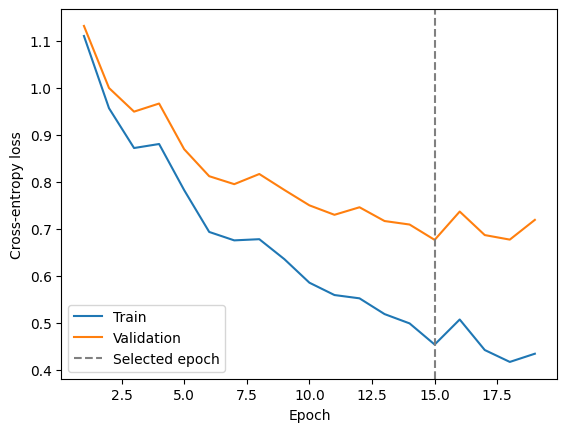

In [ ]:
import matplotlib.pyplot as plt

history = json.loads((run_dir / (chosen["name"] + "_history.json")).read_text())
epochs = [row["epoch"] for row in history]
plt.plot(epochs, [row["train_loss"] for row in history], label="Train")
plt.plot(epochs, [row["val_loss"] for row in history], label="Validation")
plt.axvline(chosen["epoch"], linestyle="--", color="gray", label="Selected epoch")
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.legend()
plt.show()

In [ ]:
saved = torch.load(chosen["checkpoint"], map_location=device, weights_only=True)
config = saved["config"]
model = CNN(len(saved["classes"]), config["dropout"], config["batchnorm"]).to(device)
model.load_state_dict(saved["state"])
test_loss, test_acc = measure(model, test_loader)
train_loss, train_acc = measure(model, train_eval_loader)
val_loss, val_acc = measure(model, val_loader)

print("선택 모델:", config["name"], "| 선택 회차:", saved["epoch"])
print(f"학습 정확도 {train_acc:.2%} | 검증 정확도 {val_acc:.2%} | 시험 정확도 {test_acc:.2%}")
print(f"시험 손실 {test_loss:.4f}")

correct = torch.zeros(len(source.classes))
total = torch.zeros(len(source.classes))
model.eval()
with torch.no_grad():
    for x, y in test_loader:
        pred = model(x.to(device)).argmax(dim=1).cpu()
        for c in range(len(source.classes)):
            mask = y == c
            total[c] += mask.sum()
            correct[c] += (pred[mask] == c).sum()

recall = correct / total.clamp_min(1)
for name, hit, count, rate in zip(source.classes, correct, total, recall):
    print(f"{name:12s} {int(hit):4d}/{int(count):4d} | 재현율 {rate:.2%}")
print(f"클래스 평균 재현율 {recall[total > 0].mean():.2%}")
(run_dir / "test_result.json").write_text(json.dumps(
    {"model": config["name"], "train_acc": train_acc, "val_acc": val_acc,
     "test_acc": test_acc, "test_loss": test_loss,
     "classes": source.classes, "recall": recall.tolist()}, indent=2), encoding="utf-8")

선택 모델: combo_low_lr | 선택 회차: 15
학습 정확도 85.58% | 검증 정확도 76.83% | 시험 정확도 77.78%
시험 손실 0.6924
battery        97/ 141 | 재현율 68.79%
biological    115/ 147 | 재현율 78.23%
brown-glass    58/  91 | 재현율 63.74%
cardboard      96/ 133 | 재현율 72.18%
clothes       759/ 798 | 재현율 95.11%
green-glass    85/  92 | 재현율 92.39%
metal          60/ 115 | 재현율 52.17%
paper         120/ 157 | 재현율 76.43%
plastic        61/ 129 | 재현율 47.29%
shoes         217/ 296 | 재현율 73.31%
trash          81/ 104 | 재현율 77.88%
white-glass    54/ 115 | 재현율 46.96%
클래스 평균 재현율 70.37%


674